# Extra: Transformer para pronóstico horario de bicicletas

## Objetivo y aporte
Implementar desde cero un Transformer pequeño que pronostique la demanda de la siguiente hora a partir de las 24 horas anteriores. Es una implementación adicional para los puntos extra; no sustituye la LSTM obligatoria. No se utilizan pesos preentrenados.

## Datos y metodología
Se usa [Bike Sharing de UCI](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset), Hadi Fanaee-T (2013), DOI 10.24432/C5W894, CC BY 4.0. Se mantienen las mismas ventanas, variables y fechas del notebook 03_RNN: calendario cronológico 70/15/15, escaladores ajustados solo con entrenamiento, ventanas completas de 24 horas y disponibilidad del rezago semanal. Los huecos no se rellenan con demandas inventadas.

## Arquitectura
La secuencia de 9 variables se proyecta a dimensión 32 y se suma un embedding posicional aprendido para posiciones 0–23. Se comparan 1 y 2 bloques Transformer: self-attention causal con 2 cabezas de dimensión 16, conexión residual, LayerNormalization, red feed-forward 64/GELU→32 y otra conexión residual con normalización. La representación de la última hora alimenta Dense 16/ReLU y salida lineal. Dropout 0.1 regula los bloques.

Se implementa con capas de Keras: [MultiHeadAttention](https://keras.io/api/layers/attention_layers/multi_head_attention/), siguiendo los componentes de [Attention Is All You Need](https://arxiv.org/abs/1706.03762). Se verifican las dimensiones y que la máscara causal anule la atención a posiciones futuras de la ventana. Los pesos de atención se visualizarán sobre un ejemplo de validación; no son una explicación causal.

## Protocolo fijado
Adam 0.001 con clipnorm 1, MSE estandarizado, batch 64, máximo 25 épocas, early stopping con paciencia 5 y checkpoints. Se elige el número de bloques por MAE de validación (RMSE como desempate). La predicción se desescala y limita a cero, sin redondeo.

Prueba corresponde al mismo periodo ya examinado en la LSTM: es una comparación adicional, no un nuevo conjunto de prueba ciego. No se adaptarán arquitecturas ni hiperparámetros según sus resultados. La referencia LSTM se identificará como resultado previamente documentado, no como un reentrenamiento en este notebook.

## Ejecución
Ejecutar todas las celdas en orden en Colab; CPU es suficiente e internet se requiere para la descarga. Los archivos se guardan en `/content/resultados_transformer`, carpeta temporal. Los modelos, métricas y figuras no se incluyen automáticamente al guardar el notebook; las salidas visibles sí se conservan.

TensorFlow: 2.21.0
Registros: 17379 | Horas ausentes: 165


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
timestamp,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
2011-01-01 01:00:00,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2011-01-01 02:00:00,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
2011-01-01 03:00:00,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
2011-01-01 04:00:00,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


,count,mean,std,min,25%,50%,75%,max
cnt,12155.0,159.832497,152.548718,1.000000,34.000000,1.190000e+02,234.000000,957.000000
temp,12155.0,0.467908,0.188474,0.020000,0.320000,4.600000e-01,0.620000,0.960000
hum,12155.0,0.627187,0.200341,0.000000,0.470000,6.200000e-01,0.790000,1.000000
windspeed,12155.0,0.196155,0.125100,0.000000,0.104500,1.940000e-01,0.283600,0.850700
workingday,12155.0,0.685150,0.464475,0.000000,0.000000,1.000000e+00,1.000000,1.000000
hour_sin,12280.0,0.000499,0.707067,-1.000000,-0.707107,1.224647e-16,0.707107,1.000000
hour_cos,12280.0,-0.000207,0.707204,-1.000000,-0.707107,-1.836970e-16,0.707107,1.000000
weekday_sin,12280.0,-0.001270,0.707549,-0.974928,-0.781831,0.000000e+00,0.781831,0.974928
weekday_cos,12280.0,-0.000290,0.706720,-0.900969,-0.900969,-2.225209e-01,0.623490,1.000000


,Partición,Ventanas,Inicio objetivo,Fin objetivo
0,train,10483,2011-01-08 04:00:00,2012-05-26 15:00:00
1,validation,2632,2012-05-26 16:00:00,2012-09-13 07:00:00
2,test,2435,2012-09-13 08:00:00,2012-12-31 23:00:00


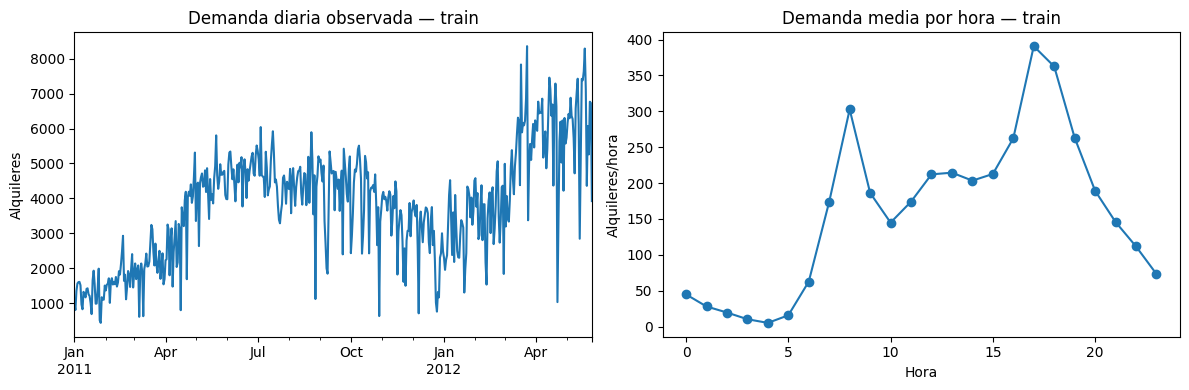

VERIFICACIÓN TEMPORAL CORRECTA: mismas ventanas y fronteras que la LSTM.


In [1]:
# 1. Descarga, auditoría y ventanas idénticas a 03_RNN
import io, zipfile, json, hashlib
from urllib.request import urlopen
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import Markdown, display
import joblib
SEED, WINDOW = 42, 24
keras.utils.set_random_seed(SEED)
OUT = Path('/content/resultados_transformer')
OUT.mkdir(parents=True, exist_ok=True)
URL = 'https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip'
with urlopen(URL, timeout=60) as response:
    raw_zip = response.read()
source_hash = hashlib.sha256(raw_zip).hexdigest()
with zipfile.ZipFile(io.BytesIO(raw_zip)) as archive:
    names = [n for n in archive.namelist() if n.endswith('hour.csv')]
    assert len(names) == 1
    with archive.open(names[0]) as file:
        bike = pd.read_csv(file)
assert bike.isna().sum().sum() == 0
assert (bike['cnt'] == bike['casual'] + bike['registered']).all()
bike['timestamp'] = pd.to_datetime(bike['dteday']) + pd.to_timedelta(bike['hr'], unit='h')
assert not bike['timestamp'].duplicated().any()
bike = bike.sort_values('timestamp').set_index('timestamp')
grid = bike.reindex(pd.date_range(bike.index.min(), bike.index.max(), freq='h'))
train_end, val_end = int(len(grid)*0.70), int(len(grid)*0.85)
features = grid[['cnt','temp','hum','windspeed','workingday']].copy()
features['hour_sin'] = np.sin(2*np.pi*grid.index.hour/24)
features['hour_cos'] = np.cos(2*np.pi*grid.index.hour/24)
features['weekday_sin'] = np.sin(2*np.pi*grid.index.dayofweek/7)
features['weekday_cos'] = np.cos(2*np.pi*grid.index.dayofweek/7)
feature_columns = features.columns.tolist()
assert not {'casual','registered','instant'} & set(feature_columns)
input_scaler = StandardScaler().fit(features.iloc[:train_end].dropna())
target_scaler = StandardScaler().fit(grid.iloc[:train_end][['cnt']].dropna().to_numpy())
scaled = input_scaler.transform(features).astype(np.float32)
counts = grid['cnt'].to_numpy(dtype=float)
x, y, target_positions, lag1, lag24, lag168 = [], [], [], [], [], []
for t in range(168, len(grid)):
    history = scaled[t-WINDOW:t]
    if not np.isfinite(history).all() or not np.isfinite(counts[[t,t-1,t-24,t-168]]).all():
        continue
    x.append(history)
    y.append(counts[t])
    target_positions.append(t)
    lag1.append(counts[t-1]); lag24.append(counts[t-24]); lag168.append(counts[t-168])
X = np.asarray(x, dtype=np.float32)
y = np.asarray(y, dtype=np.float32)
target_positions = np.asarray(target_positions)
target_times = grid.index[target_positions]
masks = {'train': target_positions < train_end,
         'validation': (target_positions >= train_end) & (target_positions < val_end),
         'test': target_positions >= val_end}
parts = {name: {'X': X[mask], 'y': y[mask], 'times': target_times[mask],
                'y_scaled': target_scaler.transform(y[mask,None]).astype(np.float32)}
         for name,mask in masks.items()}
assert X.shape[1:] == (24,9) and np.isfinite(X).all()
assert target_times.is_unique and target_times.is_monotonic_increasing
assert parts['train']['times'].max() < parts['validation']['times'].min()
assert parts['validation']['times'].max() < parts['test']['times'].min()
assert np.all((target_times-grid.index[target_positions-WINDOW]) == pd.Timedelta(hours=WINDOW))
assert [len(parts[n]['y']) for n in ['train','validation','test']] == [10483,2632,2435]
baseline_predictions = {'Persistencia': np.asarray(lag1), 'Día anterior': np.asarray(lag24),
                        'Semana anterior': np.asarray(lag168)}
print('TensorFlow:', tf.__version__)
print('Registros:', len(bike), '| Horas ausentes:', int(grid['cnt'].isna().sum()))
display(bike.head())
display(features.iloc[:train_end].describe().T)
display(pd.DataFrame([{'Partición': n, 'Ventanas': len(p['y']),
                      'Inicio objetivo': p['times'].min(), 'Fin objetivo': p['times'].max()}
                     for n,p in parts.items()]))
fig, axes = plt.subplots(1,2,figsize=(12,4))
grid.iloc[:train_end]['cnt'].resample('D').sum(min_count=1).plot(ax=axes[0])
axes[0].set(title='Demanda diaria observada — train', ylabel='Alquileres')
grid.iloc[:train_end].groupby(grid.index[:train_end].hour)['cnt'].mean().plot(ax=axes[1],marker='o')
axes[1].set(title='Demanda media por hora — train', xlabel='Hora',ylabel='Alquileres/hora')
fig.tight_layout(); fig.savefig(OUT/'exploracion.png',dpi=160); plt.show()
print('VERIFICACIÓN TEMPORAL CORRECTA: mismas ventanas y fronteras que la LSTM.')


## 2. Modelo y entrenamiento

La atención permite combinar directamente las horas de la ventana; el embedding posicional conserva su orden. Cada bloque usa atención causal, dos conexiones residuales, normalización y red feed-forward. A diferencia de la LSTM, no existe estado recurrente.

Se implementa el grafo con capas nativas serializables de Keras. La entrada auxiliar de posiciones es determinista (0–23), no contiene información del objetivo. Se comprueba antes de entrenar que las posiciones posteriores a cada consulta reciban atención cero. Se conservan checkpoints por pérdida de validación y se elige entre uno o dos bloques usando únicamente MAE de validación.


EXPERIMENTO: Transformer 1 bloques


Model: "transformer_1_bloques"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sequence            │ (None, 24, 9)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ position            │ (None, 24)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ proyeccion (Dense)  │ (None, 24, 32)    │        320 │ sequence[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ posiciones_aprendi… │ (None, 24, 32)    │        768 │ position[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ contenido_mas_posi… │ (None, 24, 32)    │          0 │ proyeccion[0][0], │
│ (Add)               │                   │            │ posiciones_apren… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ atencion_0          │ [(None, 24, 32),  │      4,224 │ contenido_mas_po… │
│ (MultiHeadAttentio… │ (None, 2, 24,     │            │ contenido_mas_po… │
│                     │ 24)]              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 24, 32)    │          0 │ atencion_0[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 24, 32)    │          0 │ contenido_mas_po… │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 24, 32)    │         64 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 24, 64)    │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 24, 32)    │      2,080 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 24, 32)    │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 24, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 24, 32)    │         64 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ultima_hora         │ (None, 1, 32)     │          0 │ layer_normalizat… │
│ (Cropping1D)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 32)        │          0 │ ultima_hora[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 16)        │        528 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ demanda_estandariz… │ (None, 1)         │         17 │ dense_2[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 10,177 (39.75 KB)

 Trainable params: 10,177 (39.75 KB)

 Non-trainable params: 0 (0.00 B)

... (5 outputs left out)

 Non-trainable params: 0 (0.00 B)

Máscara causal y dimensiones verificadas.
Epoch 1/25
164/164 - 15s - 91ms/step - loss: 0.3014 - mae_scaled: 0.3967 - val_loss: 0.3979 - val_mae_scaled: 0.4317
Epoch 2/25
164/164 - 8s - 47ms/step - loss: 0.1553 - mae_scaled: 0.2839 - val_loss: 0.2410 - val_mae_scaled: 0.3376
Epoch 3/25
164/164 - 7s - 44ms/step - loss: 0.1059 - mae_scaled: 0.2335 - val_loss: 0.1756 - val_mae_scaled: 0.2913
Epoch 4/25
164/164 - 8s - 46ms/step - loss: 0.0903 - mae_scaled: 0.2140 - val_loss: 0.1485 - val_mae_scaled: 0.2694
Epoch 5/25
164/164 - 7s - 43ms/step - loss: 0.0803 - mae_scaled: 0.1999 - val_loss: 0.1459 - val_mae_scaled: 0.2603
Epoch 6/25
164/164 - 9s - 58ms/step - loss: 0.0749 - mae_scaled: 0.1930 - val_loss: 0.1416 - val_mae_scaled: 0.2592
Epoch 7/25
164/164 - 8s - 47ms/step - loss: 0.0707 - mae_scaled: 0.1867 - val_loss: 0.1289 - val_mae_scaled: 0.2480
Epoch 8/25
164/164 - 6s - 38ms/step - loss: 0.0666 - mae_scaled: 0.1796 - val_loss: 0.1297 - val_mae_scaled: 0.2507
Epoch 9/25
164/164 - 8s - 48m

,MAE,RMSE,R2,Mejor época,Épocas ejecutadas
Modelo,,,,,
Persistencia,92.0616,135.2529,0.6344,0,0
Día anterior,81.6440,136.9121,0.6253,0,0
Semana anterior,57.6539,97.8909,0.8085,0,0
Transformer 1 bloques,32.8585,48.4117,0.9532,22,25
Transformer 2 bloques,33.6107,48.5995,0.9528,19,24


CONFIGURACIÓN FIJADA CON VALIDACIÓN: Transformer 1 bloques


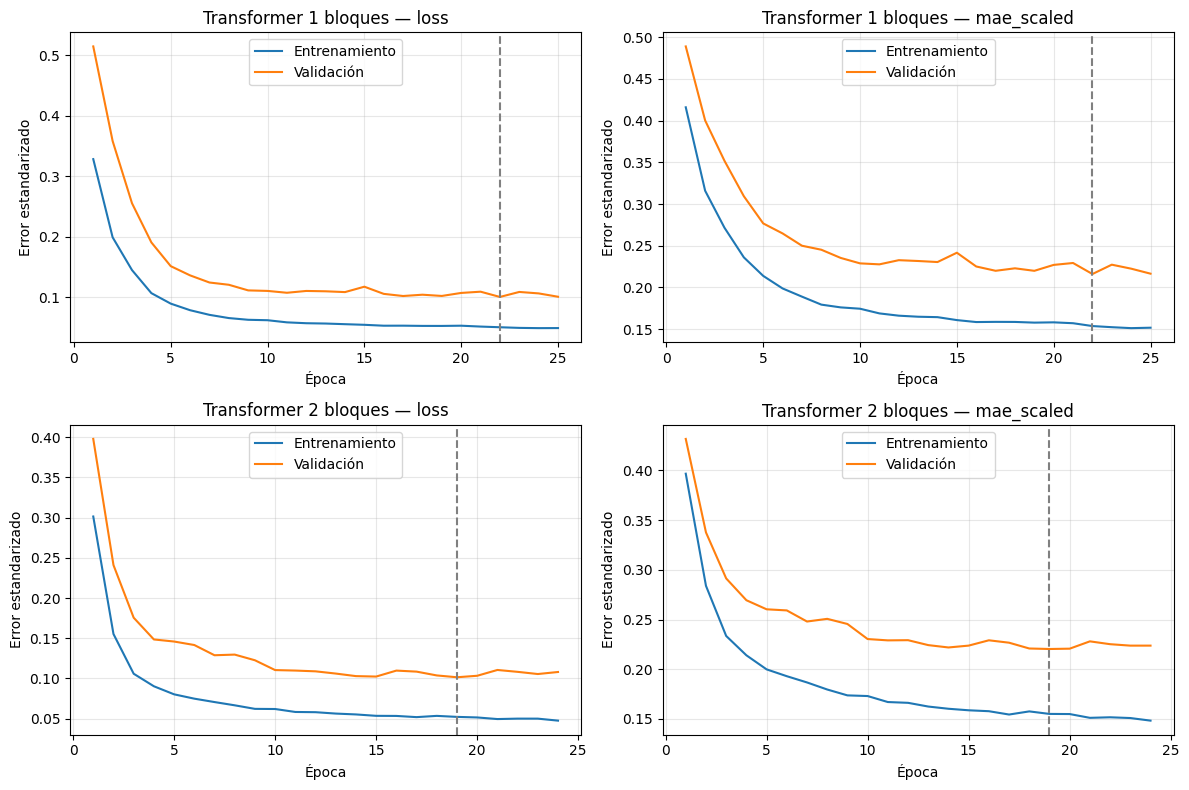

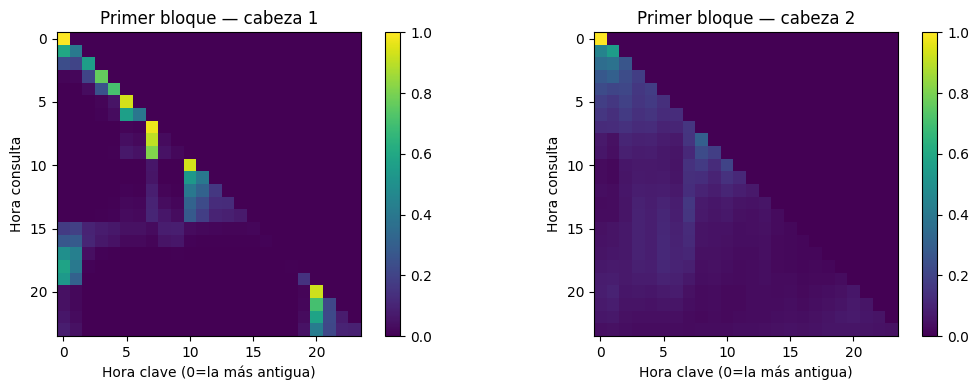

In [2]:
# 2. Transformer desde cero: proyección + posición + bloques de atención
MAX_EPOCHS, BATCH_SIZE = 25, 64
D_MODEL, NUM_HEADS, FF_DIM = 32, 2, 64

def with_positions(x):
    return {'sequence': x, 'position': np.tile(np.arange(WINDOW,dtype=np.int32),(len(x),1))}

def metrics(actual,predicted):
    return {'MAE':mean_absolute_error(actual,predicted),
            'RMSE':float(np.sqrt(mean_squared_error(actual,predicted))),
            'R2':r2_score(actual,predicted)}

def forecast(model,x):
    z = model.predict(with_positions(x),batch_size=256,verbose=0)
    return np.maximum(0,target_scaler.inverse_transform(z).ravel())

def build_transformer(n_blocks):
    sequence = keras.Input((WINDOW,len(feature_columns)),name='sequence')
    position = keras.Input((WINDOW,),dtype='int32',name='position')
    projected = layers.Dense(D_MODEL,name='proyeccion')(sequence)
    positional = layers.Embedding(WINDOW,D_MODEL,name='posiciones_aprendidas')(position)
    x = layers.Add(name='contenido_mas_posicion')([projected,positional])
    first_scores = None
    for block in range(n_blocks):
        attention,scores = layers.MultiHeadAttention(num_heads=NUM_HEADS,key_dim=D_MODEL//NUM_HEADS,
            dropout=0.1,flash_attention=False,name=f'atencion_{block}')(
                x,x,use_causal_mask=True,return_attention_scores=True)
        if first_scores is None:
            first_scores = scores
        attention = layers.Dropout(0.1,seed=SEED+block)(attention)
        x = layers.LayerNormalization(epsilon=1e-6)(layers.Add()([x,attention]))
        feedforward = layers.Dense(FF_DIM,activation='gelu')(x)
        feedforward = layers.Dense(D_MODEL)(feedforward)
        feedforward = layers.Dropout(0.1,seed=SEED+10+block)(feedforward)
        x = layers.LayerNormalization(epsilon=1e-6)(layers.Add()([x,feedforward]))
    x = layers.Cropping1D(cropping=(WINDOW-1,0),name='ultima_hora')(x)
    x = layers.Flatten()(x)
    x = layers.Dense(16,activation='relu')(x)
    output = layers.Dense(1,name='demanda_estandarizada')(x)
    inputs = {'sequence':sequence,'position':position}
    model = keras.Model(inputs,output,name=f'transformer_{n_blocks}_bloques')
    probe = keras.Model(inputs,first_scores,name=f'sonda_atencion_{n_blocks}')
    model.compile(optimizer=keras.optimizers.Adam(0.001,clipnorm=1.0),loss='mse',
                  metrics=[keras.metrics.MeanAbsoluteError(name='mae_scaled')])
    return model,probe

rows=[]
for name,p in baseline_predictions.items():
    rows.append({'Modelo':name,**metrics(parts['validation']['y'],p[masks['validation']]),
                 'Mejor época':0,'Épocas ejecutadas':0})
models,probes,histories = {},{},{}
for blocks in [1,2]:
    keras.utils.set_random_seed(SEED)
    model,probe = build_transformer(blocks)
    name=f'Transformer {blocks} bloques'
    print(chr(10)+'EXPERIMENTO: '+name)
    model.summary()
    smoke=model(with_positions(parts['train']['X'][:2]),training=False).numpy()
    attention_test=probe(with_positions(parts['train']['X'][:2]),training=False).numpy()
    assert smoke.shape==(2,1) and np.isfinite(smoke).all()
    assert attention_test.shape==(2,NUM_HEADS,WINDOW,WINDOW)
    assert np.max(np.abs(np.triu(attention_test,k=1))) < 1e-6
    print('Máscara causal y dimensiones verificadas.')
    checkpoint=OUT/f'transformer_{blocks}.weights.h5'
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True),
               keras.callbacks.ModelCheckpoint(str(checkpoint),monitor='val_loss',save_best_only=True,save_weights_only=True),
               keras.callbacks.TerminateOnNaN()]
    run=model.fit(with_positions(parts['train']['X']),parts['train']['y_scaled'],
        validation_data=(with_positions(parts['validation']['X']),parts['validation']['y_scaled']),
        epochs=MAX_EPOCHS,batch_size=BATCH_SIZE,shuffle=False,callbacks=callbacks,verbose=2)
    assert np.isfinite(run.history['loss']).all()
    model.load_weights(str(checkpoint))
    p=forecast(model,parts['validation']['X'])
    assert np.isfinite(p).all()
    models[name],probes[name],histories[name]=model,probe,run.history
    rows.append({'Modelo':name,**metrics(parts['validation']['y'],p),
                 'Mejor época':int(np.argmin(run.history['val_loss']))+1,
                 'Épocas ejecutadas':len(run.history['loss'])})
    pd.DataFrame(run.history).to_csv(OUT/f'historial_{blocks}_bloques.csv',index=False)
validation_results=pd.DataFrame(rows).set_index('Modelo')
display(validation_results.round(4))
selected_name=validation_results.loc[list(models)].sort_values(['MAE','RMSE']).index[0]
selected_baseline=validation_results.loc[list(baseline_predictions)].sort_values(['MAE','RMSE']).index[0]
selected_model=models[selected_name]
print('CONFIGURACIÓN FIJADA CON VALIDACIÓN:',selected_name)
validation_results.to_csv(OUT/'comparacion_validacion.csv')
fig,axes=plt.subplots(2,2,figsize=(12,8))
for row,(name,hist) in enumerate(histories.items()):
    for col,metric in enumerate(['loss','mae_scaled']):
        ax=axes[row,col]; ep=np.arange(1,len(hist[metric])+1)
        ax.plot(ep,hist[metric],label='Entrenamiento')
        ax.plot(ep,hist['val_'+metric],label='Validación')
        ax.axvline(int(np.argmin(hist['val_loss']))+1,color='gray',linestyle='--')
        ax.set(title=f'{name} — {metric}',xlabel='Época',ylabel='Error estandarizado')
        ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(OUT/'curvas_entrenamiento.png',dpi=160); plt.show()
# Mostrar la atención solo sobre validación.
attention=probes[selected_name](with_positions(parts['validation']['X'][:1]),training=False).numpy()[0]
fig,axes=plt.subplots(1,NUM_HEADS,figsize=(11,4))
for head,ax in enumerate(axes):
    im=ax.imshow(attention[head],cmap='viridis',vmin=0,vmax=1)
    ax.set(title=f'Primer bloque — cabeza {head+1}',xlabel='Hora clave (0=la más antigua)',ylabel='Hora consulta')
    fig.colorbar(im,ax=ax)
fig.tight_layout(); fig.savefig(OUT/'atencion_validacion.png',dpi=160); plt.show()


## 3. Evaluación, comparación y guardado

Se evalúa el Transformer elegido con validación y las referencias sobre las mismas 2,435 fechas de prueba de la LSTM. La fila LSTM 32 se incorpora como resultado histórico del notebook 03_RNN (MAE 31.6875, RMSE 47.9959, R² 0.9505), identificado expresamente; no se reentrena ni se selecciona de nuevo. La comparación es descriptiva porque el periodo de prueba ya era conocido.

Se mostrarán pronósticos, observados frente a predichos, residuos y ejemplos de errores. Se guardan modelo, escaladores, posiciones, métricas, historiales y configuración en `/content/resultados_transformer`. La recarga se comprueba desde ventanas reconstruidas sin escalar. Los errores de prueba no se usarán para nuevas decisiones de entrenamiento.

PRUEBA: Transformer y referencias calculados ahora; LSTM es referencia histórica documentada.


,MAE,RMSE,R2
Modelo,,,
Persistencia,82.1622,126.1476,0.6583
Día anterior,79.6041,131.9135,0.6264
Semana anterior,64.0263,107.7723,0.7506
Transformer 1 bloques,30.3344,46.3095,0.9540
LSTM 32 — ejecución previa 03_RNN,31.6875,47.9959,0.9505


Ejemplos de menor error:


,Real,Transformer,Referencia,Residuo,Error absoluto
timestamp,,,,,
2012-11-15 22:00:00,153.0,153.009995,161.0,0.01,0.01
2012-09-13 22:00:00,251.0,250.990005,217.0,-0.01,0.01
2012-10-08 05:00:00,19.0,18.980000,36.0,-0.02,0.02


Ejemplos de mayor error:


,Real,Transformer,Referencia,Residuo,Error absoluto
timestamp,,,,,
2012-10-02 08:00:00,134.0,575.729980,805.0,441.730011,441.730011
2012-11-21 17:00:00,374.0,701.010010,583.0,327.010010,327.010010
2012-10-19 17:00:00,425.0,729.679993,837.0,304.679993,304.679993
2012-10-11 19:00:00,743.0,454.579987,534.0,-288.420013,288.420013
2012-12-31 17:00:00,164.0,406.119995,26.0,242.119995,242.119995


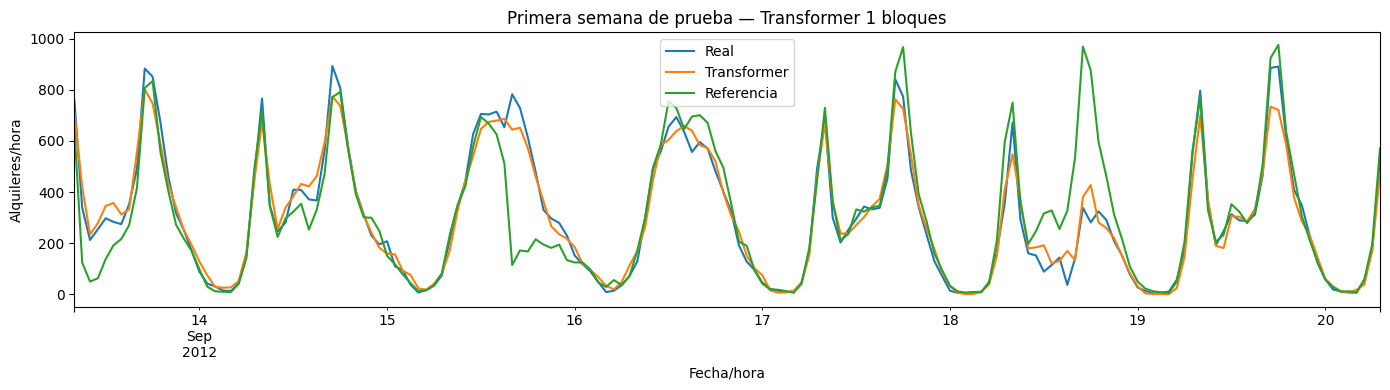

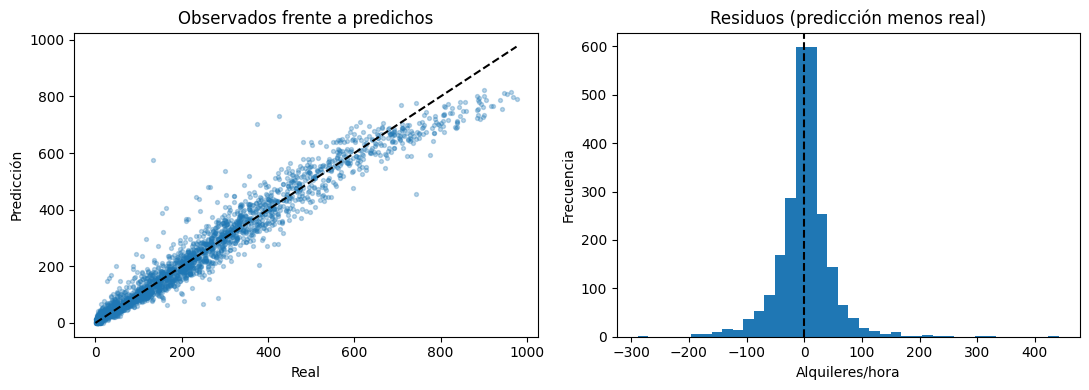

RECARGA VERIFICADA: Transformer, posiciones y ambos escaladores conservan las predicciones.


In [3]:
# 3. Evaluación adicional sobre el periodo ya documentado
predicted=forecast(selected_model,parts['test']['X'])
assert np.isfinite(predicted).all() and (predicted>=0).all()
rows=[]
for name,p in baseline_predictions.items():
    rows.append({'Modelo':name,**metrics(parts['test']['y'],p[masks['test']])})
rows.append({'Modelo':selected_name,**metrics(parts['test']['y'],predicted)})
rows.append({'Modelo':'LSTM 32 — ejecución previa 03_RNN', 'MAE':31.6875,'RMSE':47.9959,'R2':0.9505})
test_results=pd.DataFrame(rows).set_index('Modelo')
print('PRUEBA: Transformer y referencias calculados ahora; LSTM es referencia histórica documentada.')
display(test_results.round(4))
prediction_frame=pd.DataFrame({'Real':parts['test']['y'],'Transformer':predicted,
    'Referencia':baseline_predictions[selected_baseline][masks['test']]},index=parts['test']['times'])
prediction_frame.index.name='timestamp'
prediction_frame['Residuo']=prediction_frame['Transformer']-prediction_frame['Real']
prediction_frame['Error absoluto']=prediction_frame['Residuo'].abs()
print('Ejemplos de menor error:'); display(prediction_frame.nsmallest(3,'Error absoluto').round(2))
print('Ejemplos de mayor error:'); display(prediction_frame.nlargest(5,'Error absoluto').round(2))
plot_data=prediction_frame.reindex(pd.date_range(prediction_frame.index.min(),prediction_frame.index.max(),freq='h'))
week=plot_data.loc[:plot_data.index.min()+pd.Timedelta(hours=167)]
fig,ax=plt.subplots(figsize=(14,4))
week[['Real','Transformer','Referencia']].plot(ax=ax)
ax.set(title=f'Primera semana de prueba — {selected_name}',xlabel='Fecha/hora',ylabel='Alquileres/hora')
fig.tight_layout(); fig.savefig(OUT/'pronosticos.png',dpi=160); plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].scatter(parts['test']['y'],predicted,s=8,alpha=0.3)
upper=max(float(parts['test']['y'].max()),float(predicted.max()))
axes[0].plot([0,upper],[0,upper],'--',color='black')
axes[0].set(title='Observados frente a predichos',xlabel='Real',ylabel='Predicción')
axes[1].hist(prediction_frame['Residuo'],bins=40)
axes[1].axvline(0,color='black',linestyle='--')
axes[1].set(title='Residuos (predicción menos real)',xlabel='Alquileres/hora',ylabel='Frecuencia')
fig.tight_layout(); fig.savefig(OUT/'errores.png',dpi=160); plt.show()

selected_model.save(OUT/'transformer_bicicletas.keras')
joblib.dump(input_scaler,OUT/'escalador_entradas.joblib')
joblib.dump(target_scaler,OUT/'escalador_objetivo.joblib')
loaded_model=keras.models.load_model(OUT/'transformer_bicicletas.keras',compile=False)
loaded_inputs=joblib.load(OUT/'escalador_entradas.joblib')
loaded_target=joblib.load(OUT/'escalador_objetivo.joblib')
validation_positions=target_positions[masks['validation']][:12]
reconstructed=np.asarray([loaded_inputs.transform(features.iloc[t-WINDOW:t]).astype(np.float32)
                          for t in validation_positions])
reloaded=np.maximum(0,loaded_target.inverse_transform(loaded_model.predict(with_positions(reconstructed),verbose=0)).ravel())
np.testing.assert_allclose(reloaded,forecast(selected_model,parts['validation']['X'][:12]),rtol=1e-5,atol=1e-3)
np.testing.assert_allclose(selected_model.predict(with_positions(parts['validation']['X'][:12]),verbose=0),
                           loaded_model.predict(with_positions(parts['validation']['X'][:12]),verbose=0),rtol=1e-5,atol=1e-6)
from importlib.metadata import version
versions={p:version(p) for p in ['tensorflow','keras','numpy','pandas','matplotlib','scikit-learn','joblib','h5py']}
config={'dataset_url':URL,'source_sha256':source_hash,'seed':SEED,'window':WINDOW,
        'features':feature_columns,'d_model':D_MODEL,'heads':NUM_HEADS,'ff_dim':FF_DIM,
        'position_input':'int32 positions 0..23 for every sequence',
        'causal_mask':True,'selected':selected_name,'max_epochs':MAX_EPOCHS,'batch_size':BATCH_SIZE,
        'selection':'MAE validation; RMSE tie-break','test_previously_examined_in':'03_RNN.ipynb',
        'train_boundary':str(grid.index[train_end]),'test_boundary':str(grid.index[val_end]),
        'versions':versions}
(OUT/'configuracion.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')
(OUT/'requirements.txt').write_text(chr(10).join(f'{p}=={v}' for p,v in versions.items())+chr(10),encoding='utf-8')
test_results.to_csv(OUT/'metricas_prueba.csv'); prediction_frame.to_csv(OUT/'predicciones_prueba.csv')
pd.DataFrame({'timestamp':target_times,'posicion':target_positions,
    'particion':np.select([masks['train'],masks['validation']],['train','validation'],default='test')}).to_csv(OUT/'particiones.csv',index=False)
np.save(OUT/'atencion_validacion.npy',attention)
print('RECARGA VERIFICADA: Transformer, posiciones y ambos escaladores conservan las predicciones.')


## 4. Conclusiones y limitaciones

Los resultados siguientes se generan a partir de la ejecución. El interés del extra es implementar los componentes del Transformer y compararlos honestamente, no garantizar que una arquitectura supere a otra.

La comparación con LSTM es descriptiva sobre un periodo ya examinado, con una sola semilla, ventanas solapadas y una selección limitada de configuraciones. No demuestra significancia estadística ni generalización a periodos nuevos. La ausencia de historia completa excluye algunos objetivos y puede sesgar la cobertura. Los mapas de atención muestran coeficientes internos, no relaciones causales.

Como trabajo futuro se proponen una evaluación de origen móvil, nuevos periodos de prueba y un estudio controlado de historia, tamaño y regularización. No se realizarán cambios guiados por las métricas de prueba de esta entrega.

In [4]:
# 4. Conclusiones ligadas a las métricas de esta ejecución
scores=test_results.loc[selected_name]
reference=test_results.loc[selected_baseline]
previous_lstm=test_results.loc['LSTM 32 — ejecución previa 03_RNN']
change_vs_week=100*(reference['MAE']-scores['MAE'])/reference['MAE']
change_vs_lstm=100*(previous_lstm['MAE']-scores['MAE'])/previous_lstm['MAE']
word_week='redujo' if change_vs_week>=0 else 'aumentó'
word_lstm='redujo' if change_vs_lstm>=0 else 'aumentó'
hist=histories[selected_name]
best_epoch=int(np.argmin(hist['val_loss']))+1
summary=f'''### Resultados del Transformer

- Se implementó un Transformer con proyección de variables, posiciones aprendidas, atención causal multihead, conexiones residuales, LayerNormalization y red feed-forward. La variante seleccionada fue **{selected_name}**, con **{selected_model.count_params():,} parámetros**, entrenada desde cero.
- Se conservaron las **15,550 ventanas** y las fronteras del experimento LSTM: 10,483 entrenamiento, 2,632 validación y 2,435 prueba. Los escaladores se ajustaron solo con entrenamiento y ninguna entrada contiene el objetivo futuro.
- La máscara causal se verificó numéricamente antes de entrenar. Los mapas de las dos cabezas corresponden a validación y muestran el comportamiento de la atención, sin atribuirle causalidad.
- Se restauró la época **{best_epoch}** de **{len(hist['loss'])}** ejecutadas, por menor pérdida de validación. Llegar al presupuesto máximo no demuestra convergencia completa.
- En prueba obtuvo **MAE {scores['MAE']:.2f}**, **RMSE {scores['RMSE']:.2f} alquileres/hora** y **R² {scores['R2']:.4f}**.
- Frente a la referencia seleccionada **{selected_baseline}**, el Transformer **{word_week}** MAE en **{abs(change_vs_week):.2f} %**. Frente al resultado previo de LSTM 32, **{word_lstm}** MAE en **{abs(change_vs_lstm):.2f} %**. Esta comparación reutiliza un periodo ya examinado y no es una validación independiente nueva.
- La serialización y recarga del Transformer, junto con posiciones y escaladores, reprodujo la inferencia. Las curvas, pronósticos, residuos y ejemplos quedan incluidos en el notebook.
'''
display(Markdown(summary))
(OUT/'conclusiones.md').write_text(summary,encoding='utf-8')
required=['transformer_bicicletas.keras','escalador_entradas.joblib','escalador_objetivo.joblib',
          'comparacion_validacion.csv','metricas_prueba.csv','configuracion.json','requirements.txt',
          'curvas_entrenamiento.png','atencion_validacion.png','pronosticos.png','errores.png','conclusiones.md']
assert all((OUT/name).is_file() and (OUT/name).stat().st_size>0 for name in required)
assert len(prediction_frame)==2435
print('VERIFICACIÓN FINAL CORRECTA: Transformer, máscara causal, métricas, recarga y archivos.')
print(chr(10).join(sorted(p.name for p in OUT.iterdir())))


### Resultados del Transformer

- Se implementó un Transformer con proyección de variables, posiciones aprendidas, atención causal multihead, conexiones residuales, LayerNormalization y red feed-forward. La variante seleccionada fue **Transformer 1 bloques**, con **10,177 parámetros**, entrenada desde cero.
- Se conservaron las **15,550 ventanas** y las fronteras del experimento LSTM: 10,483 entrenamiento, 2,632 validación y 2,435 prueba. Los escaladores se ajustaron solo con entrenamiento y ninguna entrada contiene el objetivo futuro.
- La máscara causal se verificó numéricamente antes de entrenar. Los mapas de las dos cabezas corresponden a validación y muestran el comportamiento de la atención, sin atribuirle causalidad.
- Se restauró la época **22** de **25** ejecutadas, por menor pérdida de validación. Llegar al presupuesto máximo no demuestra convergencia completa.
- En prueba obtuvo **MAE 30.33**, **RMSE 46.31 alquileres/hora** y **R² 0.9540**.
- Frente a la referencia seleccionada **Semana anterior**, el Transformer **redujo** MAE en **52.62 %**. Frente al resultado previo de LSTM 32, **redujo** MAE en **4.27 %**. Esta comparación reutiliza un periodo ya examinado y no es una validación independiente nueva.
- La serialización y recarga del Transformer, junto con posiciones y escaladores, reprodujo la inferencia. Las curvas, pronósticos, residuos y ejemplos quedan incluidos en el notebook.


VERIFICACIÓN FINAL CORRECTA: Transformer, máscara causal, métricas, recarga y archivos.
atencion_validacion.npy
atencion_validacion.png
comparacion_validacion.csv
conclusiones.md
configuracion.json
curvas_entrenamiento.png
errores.png
escalador_entradas.joblib
escalador_objetivo.joblib
exploracion.png
historial_1_bloques.csv
historial_2_bloques.csv
metricas_prueba.csv
particiones.csv
predicciones_prueba.csv
pronosticos.png
requirements.txt
transformer_1.weights.h5
transformer_2.weights.h5
transformer_bicicletas.keras
